In [1]:
import pandas as pd
kaggle_link = "https://www.kaggle.com/datasets/uciml/student-performance-data-set"
data_link = "https://raw.githubusercontent.com/jselbaz/Student-Performance-Kaggle-Data-Set/main/student-mat.csv"
df = pd.read_csv(data_link, sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFinal Grade Statistics:")
print(df["G3"].describe())

Dataset shape: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0

Final Grade Statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

features = [
    "studytime",
    "failures",
    "absences",
    "freetime",
    "goout",
    "health",
    "famrel",
    "schoolsup",
    "famsup",
    "activities",
    "internet",
    "paid"
]

X = df[features]
y = df["G3"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Mean Absolute Error:", round(
    mean_absolute_error(y_test, y_pred), 2
))

print("R2 Score:", round(
    r2_score(y_test, y_pred), 3
))

Mean Absolute Error: 3.81
R2 Score: -0.018


In [4]:
# Compare a model using previous grades too

features_with_grades = features + ["G1", "G2"]

X2 = df[features_with_grades]
y2 = df["G3"]

X2 = pd.get_dummies(X2, drop_first=True, dtype=int)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

model2 = LinearRegression()
model2.fit(X_train2, y_train2)

predictions2 = model2.predict(X_test2)

print("Model with previous grades")
print("MAE:", round(
    mean_absolute_error(y_test2, predictions2), 2
))
print("R2:", round(
    r2_score(y_test2, predictions2), 3
))

Model with previous grades
MAE: 1.47
R2: 0.761


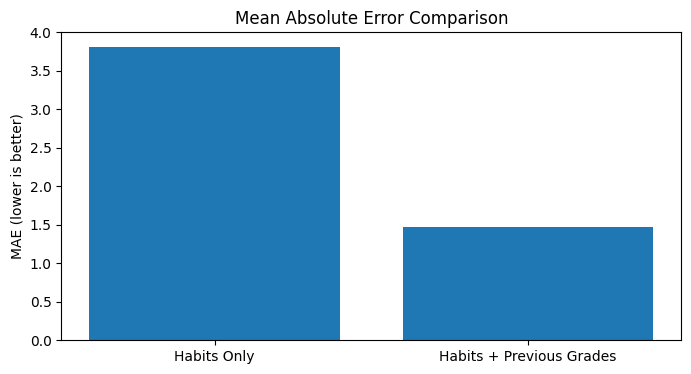

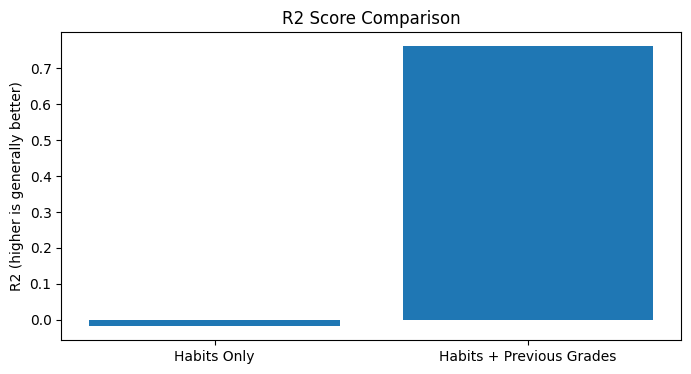

In [5]:
import matplotlib.pyplot as plt

models = ["Habits Only", "Habits + Previous Grades"]
mae_values = [3.81, 1.47]
r2_values = [-0.018, 0.761]

plt.figure(figsize=(8, 4))
plt.bar(models, mae_values)
plt.title("Mean Absolute Error Comparison")
plt.ylabel("MAE (lower is better)")
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(models, r2_values)
plt.title("R2 Score Comparison")
plt.ylabel("R2 (higher is generally better)")
plt.show()

In [7]:
new_student = pd.DataFrame([{
    "studytime": 3,
    "failures": 0,
    "absences": 2,
    "freetime": 3,
    "goout": 2,
    "health": 4,
    "famrel": 4,
    "schoolsup": "yes",
    "famsup": "yes",
    "activities": "yes",
    "internet": "yes",
    "paid": "no",
    "G1": 12,
    "G2": 14
}])

new_student = pd.get_dummies(
    new_student, drop_first=True, dtype=int
)

new_student = new_student.reindex(
    columns=X2.columns, fill_value=0
)

prediction = model2.predict(new_student)[0]

prediction = max(0, min(20, prediction))

print("Predicted Final Grade:", round(prediction, 2), "/ 20")

Predicted Final Grade: 13.78 / 20


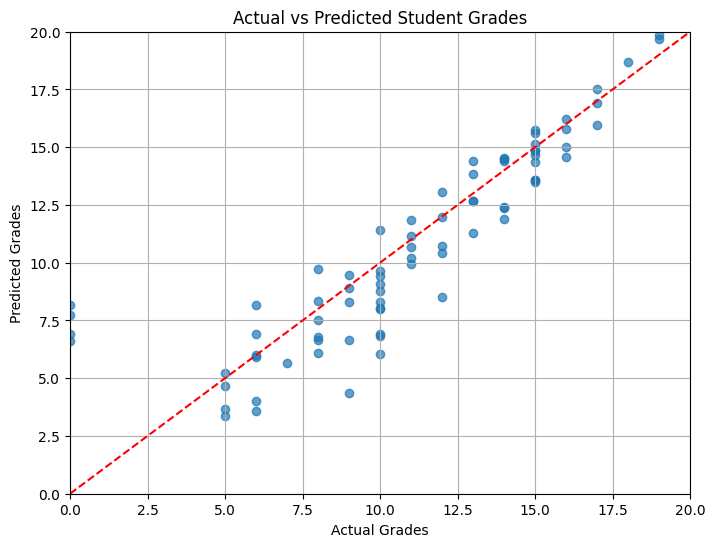

In [8]:
import matplotlib.pyplot as plt

# Compare actual grades with predicted grades
plt.figure(figsize=(8, 6))

plt.scatter(y_test2, predictions2, alpha=0.7)

# Perfect prediction reference line
plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Student Grades")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(True)
plt.show()

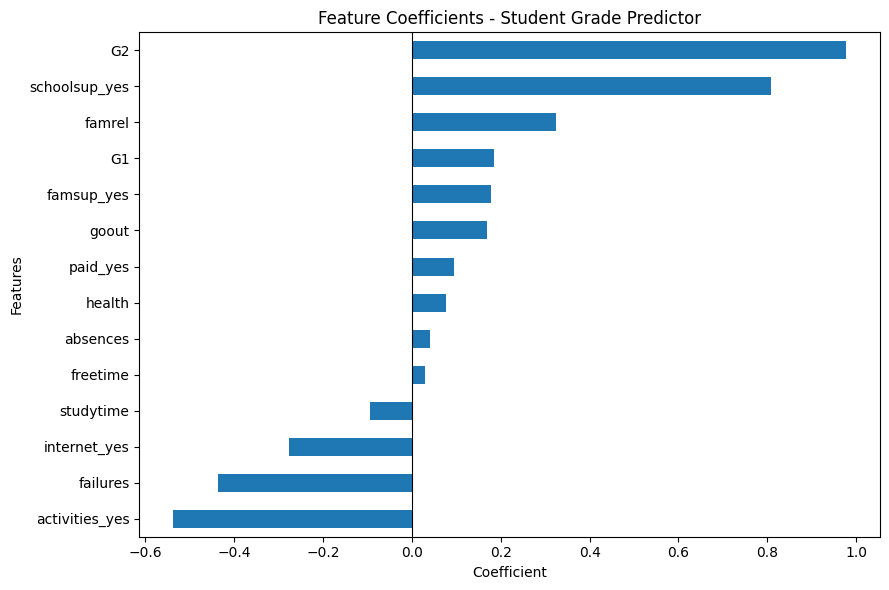

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

coefficients = pd.Series(
    model2.coef_,
    index=X2.columns
)

coefficients = coefficients.sort_values()

plt.figure(figsize=(9, 6))
coefficients.plot(kind="barh")

plt.title("Feature Coefficients - Student Grade Predictor")
plt.xlabel("Coefficient")
plt.ylabel("Features")
plt.axvline(x=0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()